# DW analysis insight graphs

This notebook creates display-only Seaborn/Matplotlib charts from `query_results.txt`. It does not save, embed, or modify any graphs.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Shared visual design based on the reference chart.
NAVY = '#142E5A'
TEXT = '#30343B'
MUTED = '#737987'
GRID = '#D9DEE7'
LATE = '#D9822B'
PALETTE = ['#A8DDB5', '#7BCBA7', '#52B3A5', '#2F97AD', '#2D78A5', '#315B96']

sns.set_theme(style='white', context='notebook', font_scale=1.05, palette=PALETTE)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.labelcolor': TEXT,
    'xtick.color': TEXT,
    'ytick.color': TEXT,
    'text.color': TEXT,
})

def style_chart(ax, title, subtitle, xlabel='', ylabel='', grid_axis='both'):
    ax.set_title(title, fontsize=20, fontweight='bold', color=NAVY, pad=42)
    ax.text(0.5, 1.06, subtitle, transform=ax.transAxes, ha='center', va='bottom',
            fontsize=12, color=MUTED)
    ax.set_xlabel(xlabel, labelpad=12)
    ax.set_ylabel(ylabel, labelpad=12)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8,
            linestyle=(0, (3, 3)), alpha=0.9)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

# Tighter dashboard variant: left-aligned heading, one grid axis, no side spines.
def style_dashboard(ax, title, subtitle, xlabel='', ylabel='', grid_axis='y'):
    ax.set_title(title, fontsize=15, fontweight='bold', color=NAVY, loc='left', pad=22)
    ax.text(0, 1.01, subtitle, transform=ax.transAxes, ha='left', va='bottom',
            fontsize=10, color=MUTED)
    ax.set_xlabel(xlabel, fontsize=10, color=MUTED, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=10, color=MUTED, labelpad=8)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.7,
            linestyle=(0, (3, 3)), alpha=0.9)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=9, length=0)
    sns.despine(ax=ax, left=True)

def style_panel(ax, title, xlabel='', ylabel='', grid_axis='x'):
    ax.set_title(title, fontsize=14, fontweight='bold', color=NAVY, pad=12)
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel(ylabel, labelpad=10)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8,
            linestyle=(0, (3, 3)), alpha=0.9)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

def add_figure_heading(fig, title, subtitle):
    fig.suptitle(title, fontsize=20, fontweight='bold', color=NAVY, y=0.98)
    fig.text(0.5, 0.925, subtitle, ha='center', va='top',
             fontsize=12, color=MUTED)


In [2]:
# Read the result tables recorded by DW_query.sql.
import re

result_file = next(path for path in (Path('query_results.txt'), Path('../query_results.txt')) if path.exists())

def read_mysql_tables(path):
    pattern = re.compile(
        r'^\+[-+]+\+\r?\n'
        r'(?P<header>\|.*\|)\r?\n'
        r'^\+[-+]+\+\r?\n'
        r'(?P<rows>(?:\|.*\|\r?\n)+)'
        r'^\+[-+]+\+$',
        flags=re.MULTILINE,
    )

    def split_row(row):
        return [value.strip() for value in row.strip().strip('|').split('|')]

    tables = []
    for match in pattern.finditer(path.read_text(encoding='utf-8')):
        header = split_row(match.group('header'))
        rows = [split_row(row) for row in match.group('rows').splitlines() if row.startswith('|')]
        tables.append(pd.DataFrame(rows, columns=header))
    if len(tables) < 6:
        raise ValueError(f'Expected at least 6 result tables, found {len(tables)}.')
    return tables

tables = read_mysql_tables(result_file)

def find_table(*required_columns):
    required = set(required_columns)
    for frame in tables:
        if required.issubset(frame.columns):
            return frame.copy()
    raise ValueError(f'No result table contains columns: {sorted(required)}')

# Identify tables by their columns, so SQL query order can change safely.
monthly = find_table('Year', 'MonthName', 'TotalLoans')
staff_table = next((frame.copy() for frame in tables
                    if {'Department', 'EmploymentType', 'CompletedLoans'}.issubset(frame.columns)), None)
weekday = find_table('DayOfWeek', 'PctOfAllLoans')
seasonal = find_table('Genre', 'Month', 'MonthName', 'TotalLoans')
member_activity = find_table('MemberID', 'TotalDurationDays')
tier = find_table('TierName', 'LatePct', 'AvgDurationDays')
genre = find_table('DistinctBooks', 'LoansPerBook')
return_table = next((frame.copy() for frame in tables
                     if {'ReturnTimingBand', 'LoanCount', 'SharePct'}.issubset(frame.columns)), None)

# Fallback Query 2 results are used when the existing text file has only six tables.
staff_workload = staff_table if staff_table is not None else pd.DataFrame([
    ['Circulation', 'Part-time', 2243, 8.84, 8.29],
    ['Circulation', 'Full-time', 1981, 8.89, 8.78],
    ['Inventory', 'Full-time', 1692, 8.57, 8.10],
    ['Digital Services', 'Part-time', 1484, 9.01, 8.89],
    ['Inventory', 'Part-time', 1463, 8.84, 8.75],
    ['Reference', 'Full-time', 1283, 8.73, 8.26],
    ['Reference', 'Part-time', 705, 8.71, 8.94],
    ['Membership', 'Part-time', 515, 7.77, 7.77],
    ['Membership', 'Full-time', 507, 8.69, 7.50],
    ['Digital Services', 'Full-time', 470, 9.18, 8.72],
], columns=['Department', 'EmploymentType', 'CompletedLoans', 'AvgLoanDurationDays', 'LateReturnRatePct'])

# Fallback Query 8 results are used until that table is added to query_results.txt.
return_bands = return_table if return_table is not None else pd.DataFrame([
    ['On time or early', 11298, 91.53, 7.37],
    ['1-3 days late', 189, 1.53, 15.86],
    ['4-7 days late', 205, 1.66, 19.54],
    ['8+ days late', 651, 5.27, 28.50],
], columns=['ReturnTimingBand', 'LoanCount', 'SharePct', 'AvgLoanDurationDays'])

for frame in (monthly, staff_workload, weekday, seasonal, member_activity, tier, genre, return_bands):
    for column in frame.columns:
        try:
            frame[column] = pd.to_numeric(frame[column])
        except (TypeError, ValueError):
            pass

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly['MonthNumber'] = monthly['MonthName'].map({name: index + 1 for index, name in enumerate(month_order)})
monthly['Period'] = pd.to_datetime(dict(year=monthly['Year'], month=monthly['MonthNumber'], day=1))
weekday['DayOfWeek'] = pd.Categorical(weekday['DayOfWeek'],
                                      categories=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
                                      ordered=True)
seasonal['MonthName'] = pd.Categorical(seasonal['MonthName'], categories=month_order, ordered=True)


## 1. Monthly loan volume by year (stacked area)

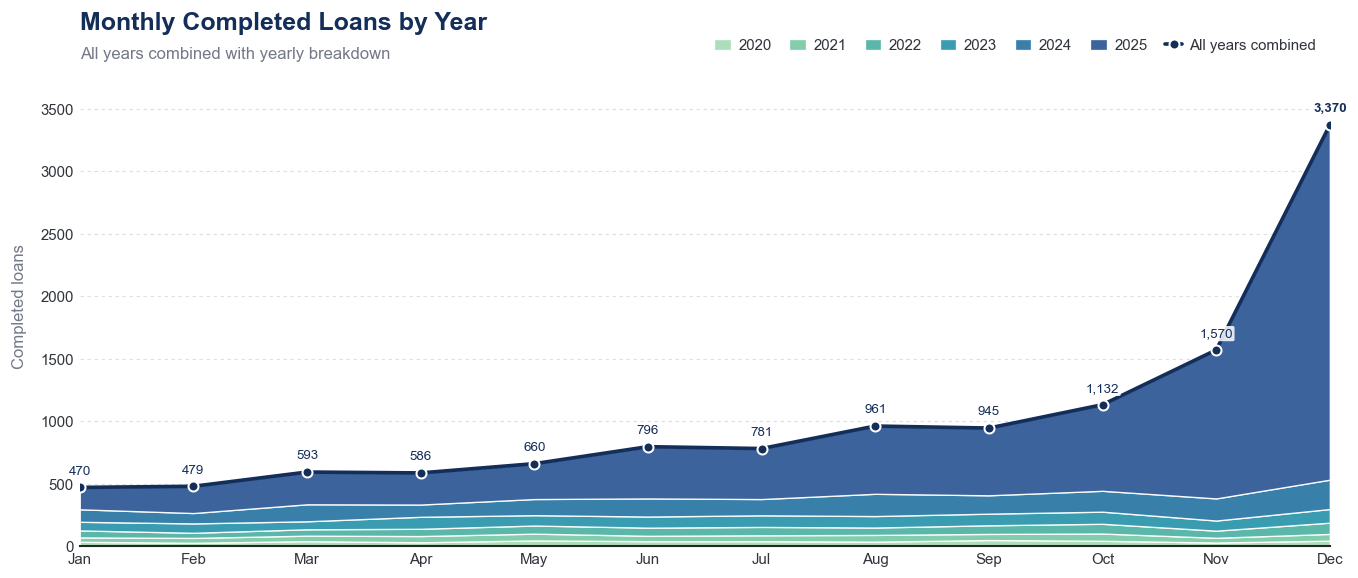

In [3]:
monthly_area = (monthly.pivot_table(index='MonthName', columns='Year', values='TotalLoans',
                                    aggfunc='sum', fill_value=0)
                .reindex(month_order))
monthly_area = monthly_area.reindex(sorted(monthly_area.columns), axis=1)

x = range(len(month_order))
colours = PALETTE[:len(monthly_area.columns)]

fig, ax = plt.subplots(figsize=(11.5, 5))
ax.stackplot(x, monthly_area.T.to_numpy(), labels=monthly_area.columns.astype(str),
             colors=colours, alpha=0.95, edgecolor='white', linewidth=0.8)

# Trace and label the combined total so the monthly peaks are easy to identify.
monthly_totals = monthly_area.sum(axis=1).to_numpy()
ax.plot(x, monthly_totals, color=NAVY, linewidth=2.2, marker='o',
        markerfacecolor=NAVY, markeredgecolor='white', markeredgewidth=1.2,
        markersize=6, label='All years combined')
peak_month = int(monthly_totals.argmax())
for i, total in enumerate(monthly_totals):
    ax.annotate(f'{int(total):,}', (i, total), xytext=(0, 8),
                textcoords='offset points', ha='center', fontsize=8,
                fontweight='bold' if i == peak_month else 'normal', color=NAVY,
                bbox=dict(boxstyle='round,pad=0.12', facecolor='white',
                          edgecolor='none', alpha=0.85))

# Short month labels and a fixed x range keep the area flush with the axes.
ax.set_xticks(x, [name[:3] for name in month_order])
ax.set_xlim(0, len(month_order) - 1)
ax.margins(y=0.14)
style_dashboard(ax, 'Monthly Completed Loans by Year',
                'All years combined with yearly breakdown',
                ylabel='Completed loans', grid_axis='y')
ax.legend(ncol=len(monthly_area.columns) + 1, frameon=False, loc='lower right',
          bbox_to_anchor=(1, 1.0), fontsize=9, handlelength=1.1,
          handletextpad=0.5, columnspacing=1.2)
fig.tight_layout()
plt.show()


## 2. Staff workload by department and employment type

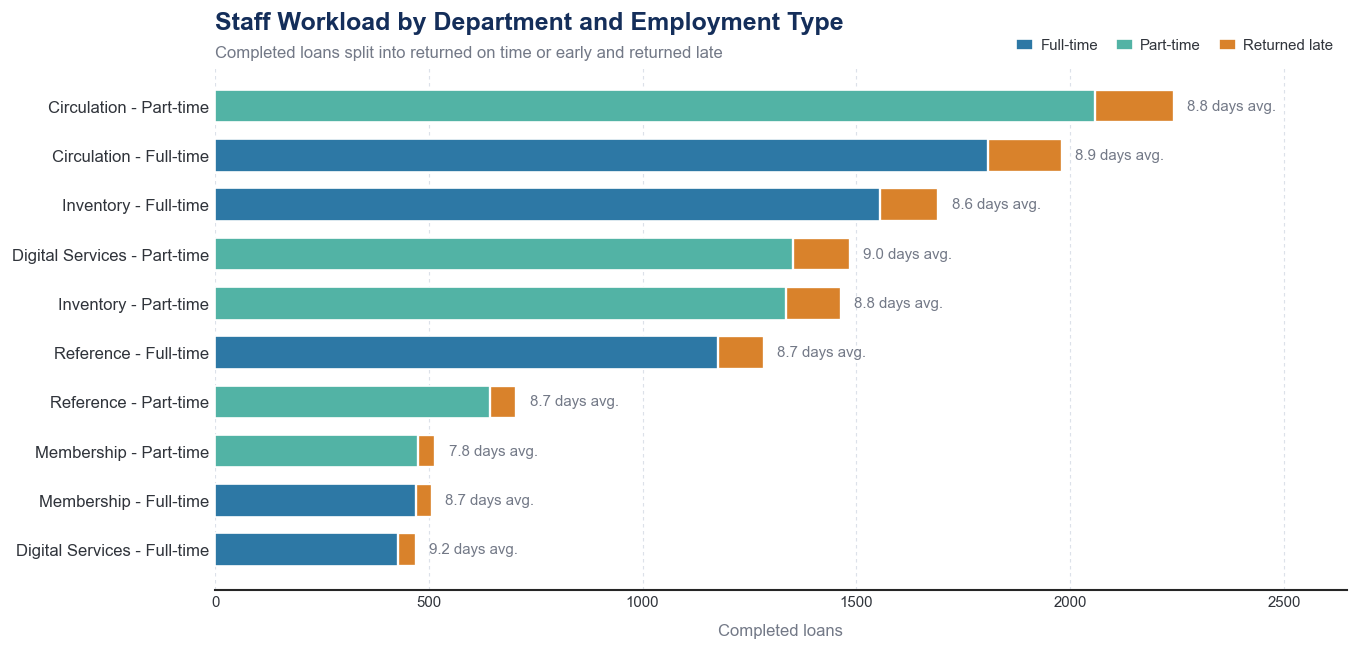

In [4]:
staff_plot = staff_workload.sort_values('CompletedLoans').copy()
staff_plot['Label'] = staff_plot['Department'] + ' - ' + staff_plot['EmploymentType']

# Split each bar into the on-time or early portion and the late portion.
staff_plot['LateLoans'] = (staff_plot['CompletedLoans'] * staff_plot['LateReturnRatePct'] / 100).round()
staff_plot['EarlyLoans'] = staff_plot['CompletedLoans'] - staff_plot['LateLoans']

type_colours = {'Full-time': PALETTE[4], 'Part-time': PALETTE[2]}
fig, ax = plt.subplots(figsize=(11.5, 5.6))
ax.barh(staff_plot['Label'], staff_plot['EarlyLoans'], height=0.66,
        color=staff_plot['EmploymentType'].map(type_colours))
ax.barh(staff_plot['Label'], staff_plot['LateLoans'], left=staff_plot['EarlyLoans'],
        height=0.66, color=LATE, edgecolor='white', linewidth=1.4)

# Average duration is the only end label now that late share is shown in the bar.
for position, (_, row) in enumerate(staff_plot.iterrows()):
    ax.annotate(f"{row['AvgLoanDurationDays']:.1f} days avg.",
                (row['CompletedLoans'], position), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=9, color=MUTED)

style_dashboard(ax, 'Staff Workload by Department and Employment Type',
                'Completed loans split into returned on time or early and returned late',
                xlabel='Completed loans', grid_axis='x')
ax.set_xlim(0, staff_plot['CompletedLoans'].max() * 1.18)
ax.tick_params(axis='y', labelsize=10)
ax.legend(handles=[Patch(facecolor=PALETTE[4], label='Full-time'),
                   Patch(facecolor=PALETTE[2], label='Part-time'),
                   Patch(facecolor=LATE, label='Returned late')],
          ncol=3, frameon=False, loc='lower right', bbox_to_anchor=(1, 1.0),
          fontsize=9, handlelength=1.1, handletextpad=0.5, columnspacing=1.2)
fig.tight_layout()
plt.show()


## 3. Borrowing pattern by day of week

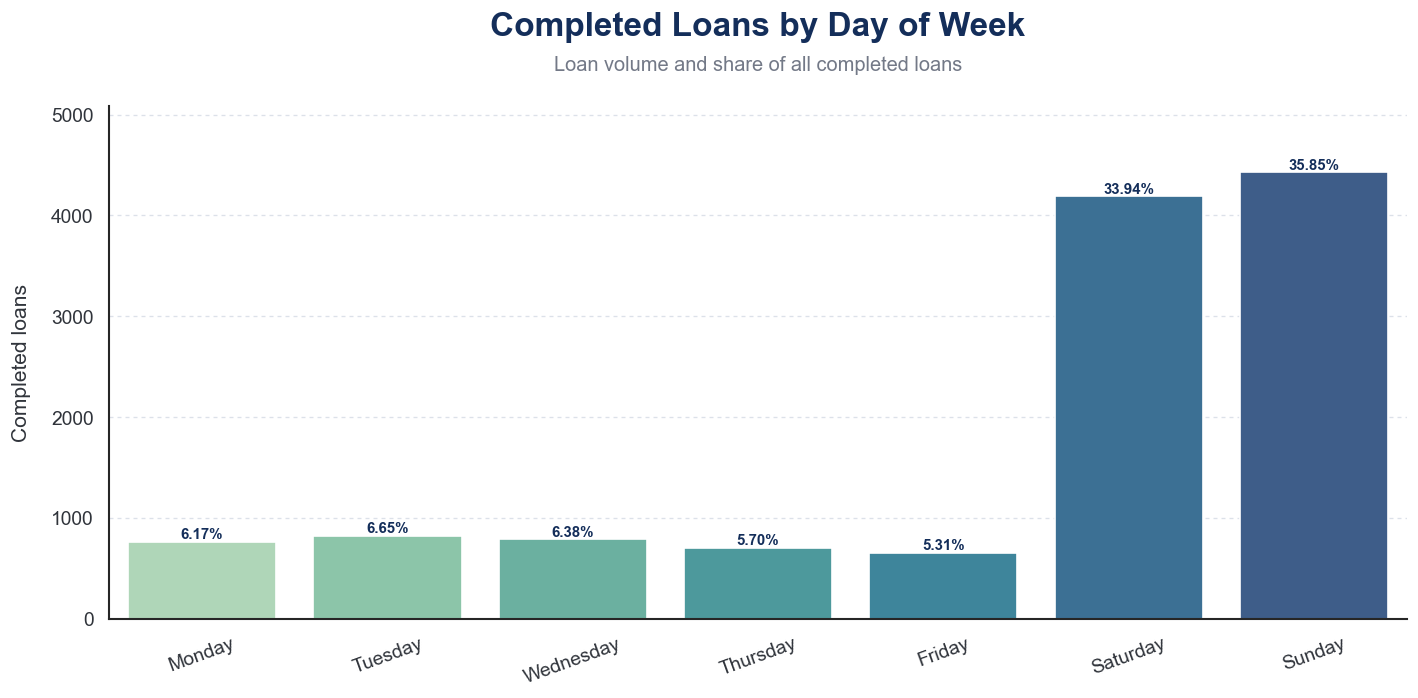

In [5]:
day_plot = weekday.sort_values('DayOfWeek')
fig, ax = plt.subplots(figsize=(12, 6))
day_colours = sns.blend_palette(PALETTE, n_colors=len(day_plot))
sns.barplot(data=day_plot, x='DayOfWeek', y='TotalLoans',
            hue='DayOfWeek', palette=day_colours, legend=False, ax=ax)
for bar, percentage in zip(ax.patches, day_plot['PctOfAllLoans']):
    ax.annotate(f'{percentage:.2f}%', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=NAVY)
style_chart(ax, 'Completed Loans by Day of Week',
            'Loan volume and share of all completed loans',
            ylabel='Completed loans', grid_axis='y')
ax.tick_params(axis='x', rotation=20)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()


## 4. Monthly demand for Children and Young Adult titles

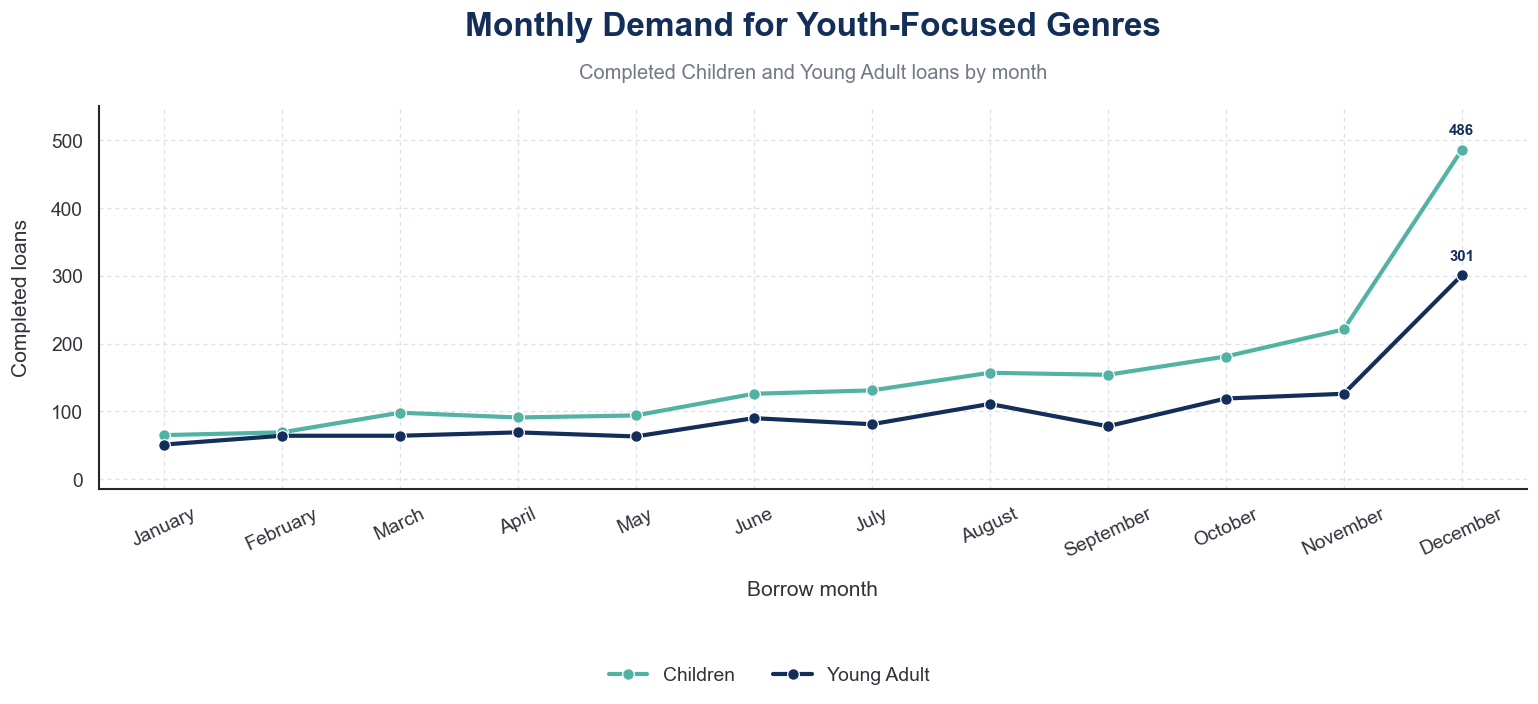

In [6]:
season_plot = seasonal.sort_values(['Genre', 'Month'])
fig, ax = plt.subplots(figsize=(13, 6))
genre_names = list(season_plot['Genre'].drop_duplicates())
genre_colours = dict(zip(genre_names, [PALETTE[2], NAVY]))
sns.lineplot(data=season_plot, x='MonthName', y='TotalLoans', hue='Genre',
             marker='o', markersize=7, linewidth=2.5, palette=genre_colours, ax=ax)
for genre_name, group in season_plot.groupby('Genre', observed=True):
    peak = group.loc[group['TotalLoans'].idxmax()]
    ax.annotate(f"{int(peak['TotalLoans']):,}",
                (peak['MonthName'], peak['TotalLoans']), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=9,
                fontweight='bold', color=NAVY)
style_chart(ax, 'Monthly Demand for Youth-Focused Genres',
            'Completed Children and Young Adult loans by month',
            xlabel='Borrow month', ylabel='Completed loans')
ax.tick_params(axis='x', rotation=25)
ax.margins(y=0.15)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles, labels, ncol=2, frameon=False, loc='lower center',
           bbox_to_anchor=(0.5, 0.01))
fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


## 5. Members with the highest and lowest borrowing activity

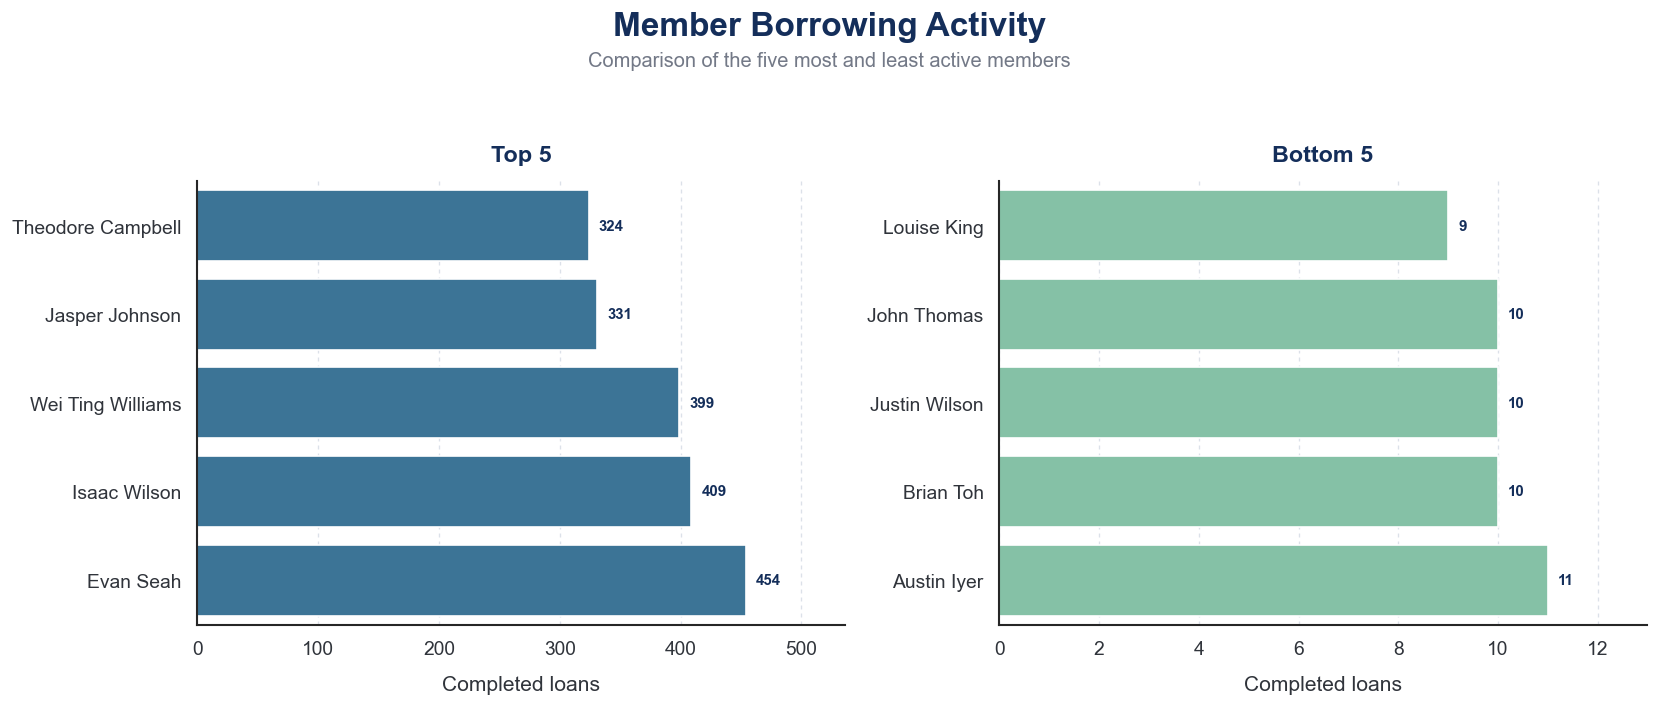

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False)
for ax, group, colour in zip(axes, ['Top 5', 'Bottom 5'], [PALETTE[4], PALETTE[1]]):
    subset = member_activity[member_activity['Grp'] == group].sort_values('TotalLoans')
    sns.barplot(data=subset, x='TotalLoans', y='Name', color=colour, ax=ax)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_width():,.0f}',
                    (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(6, 0), textcoords='offset points', va='center',
                    fontsize=9, fontweight='bold', color=NAVY)
    style_panel(ax, group, xlabel='Completed loans', grid_axis='x')
    ax.margins(x=0.18)
add_figure_heading(fig, 'Member Borrowing Activity',
                   'Comparison of the five most and least active members')
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


## 6. Average completed loans and late-return rate by membership tier

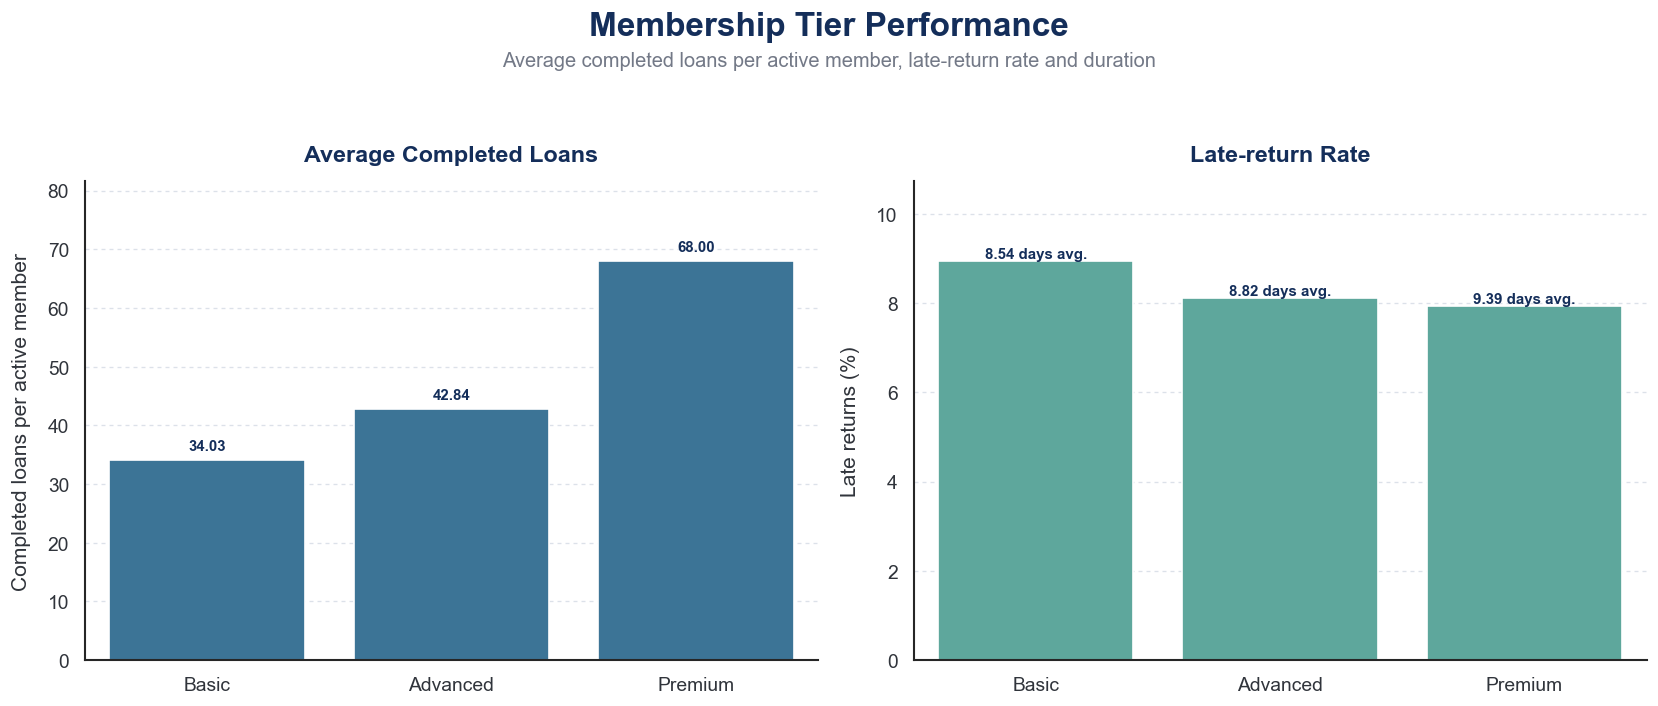

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=tier, x='TierName', y='AvgCompletedLoans', color=PALETTE[4], ax=axes[0])
for bar in axes[0].patches:
    axes[0].annotate(f'{bar.get_height():,.2f}',
                     (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 6), textcoords='offset points', ha='center',
                     fontsize=9, fontweight='bold', color=NAVY)
style_panel(axes[0], 'Average Completed Loans',
            ylabel='Completed loans per active member', grid_axis='y')
sns.barplot(data=tier, x='TierName', y='LatePct', color=PALETTE[2], ax=axes[1])
for bar, duration in zip(axes[1].patches, tier['AvgDurationDays']):
    axes[1].annotate(f'{duration:.2f} days avg.', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom', fontsize=9,
                     fontweight='bold', color=NAVY)
style_panel(axes[1], 'Late-return Rate', ylabel='Late returns (%)', grid_axis='y')
for ax in axes:
    ax.margins(y=0.20)
add_figure_heading(fig, 'Membership Tier Performance',
                   'Average completed loans per active member, late-return rate and duration')
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


## 7. Genre popularity and borrowing intensity

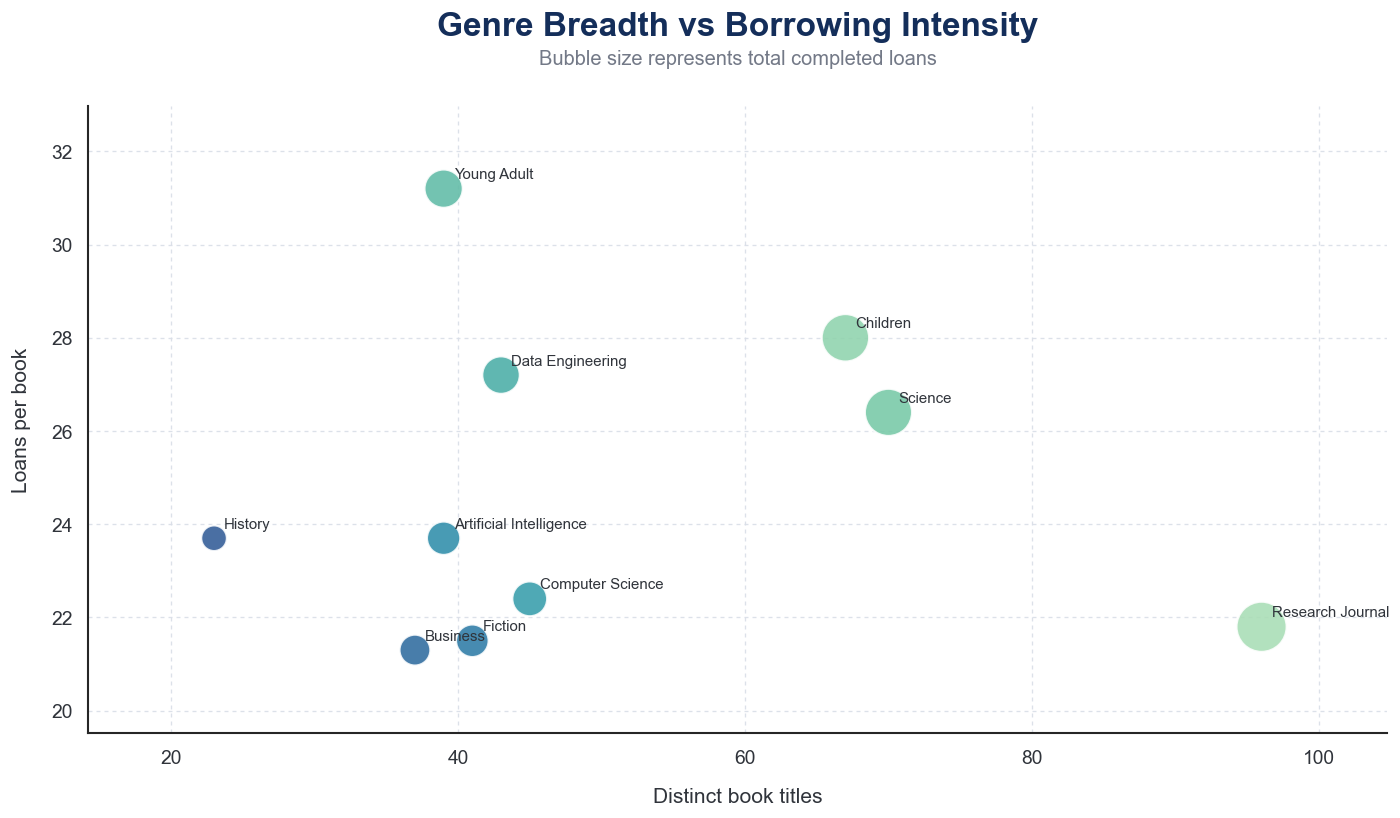

In [9]:
fig, ax = plt.subplots(figsize=(12, 7))
sizes = genre['TotalLoans'] / genre['TotalLoans'].max() * 900
point_colours = sns.blend_palette(PALETTE, n_colors=len(genre))
ax.scatter(genre['DistinctBooks'], genre['LoansPerBook'], s=sizes, alpha=0.88,
           c=point_colours, edgecolor='white', linewidth=1.2)
for _, row in genre.iterrows():
    ax.annotate(row['Genre'], (row['DistinctBooks'], row['LoansPerBook']),
                xytext=(6, 6), textcoords='offset points', fontsize=9, color=TEXT)
style_chart(ax, 'Genre Breadth vs Borrowing Intensity',
            'Bubble size represents total completed loans',
            xlabel='Distinct book titles', ylabel='Loans per book')
ax.margins(x=0.12, y=0.18)
fig.tight_layout()
plt.show()


## 8. Severity bands for late returns

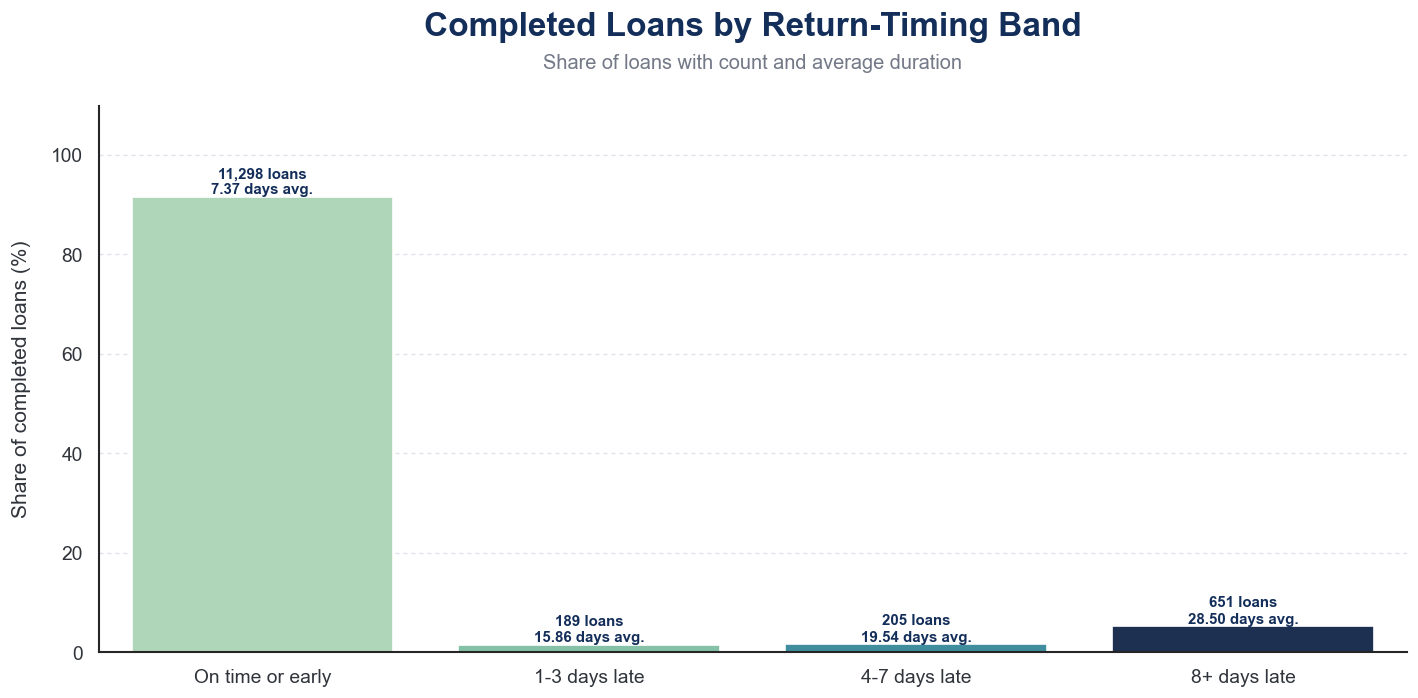

In [10]:
band_order = ['On time or early', '1-3 days late', '4-7 days late', '8+ days late']
return_bands['ReturnTimingBand'] = pd.Categorical(return_bands['ReturnTimingBand'],
                                               categories=band_order, ordered=True)
band_plot = return_bands.sort_values('ReturnTimingBand')
fig, ax = plt.subplots(figsize=(12, 6))
severity_colours = [PALETTE[0], PALETTE[1], PALETTE[3], NAVY]
sns.barplot(data=band_plot, x='ReturnTimingBand', y='SharePct',
            hue='ReturnTimingBand', palette=severity_colours, legend=False, ax=ax)
for bar, (_, row) in zip(ax.patches, band_plot.iterrows()):
    ax.annotate(f"{row['LoanCount']:,} loans\n{row['AvgLoanDurationDays']:.2f} days avg.",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9,
                fontweight='bold', color=NAVY)
style_chart(ax, 'Completed Loans by Return-Timing Band',
            'Share of loans with count and average duration',
            ylabel='Share of completed loans (%)', grid_axis='y')
ax.margins(y=0.20)
fig.tight_layout()
plt.show()
